## Dimensionality Reduction and Classification Workflow on USA States Education Data

This workflow loads real-world state educational attainment data, builds a classification target, and evaluates how PCA and t-SNE affect visualizations and classification accuracy.

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import accuracy_score

# Load the dataset
df_education = pd.read_csv('/content/Bachelors or Higher Degree for USA States.csv')
display(df_education.head())

,Unnamed: 0,Alabama,California,Arizona,Michigan,North Carolina,Minnesota,Arkansas,Montana,Georgia,...,Hawaii,Nebraska,Utah,Ohio,Washington,South Dakota,Rhode Island,Oregon,Virginia,New Hampshire
0,2006-01-01,21.1,29.0,25.5,24.5,24.8,30.4,18.2,27.4,26.6,...,29.7,26.9,28.6,23.0,30.5,24.8,29.6,27.5,32.7,31.9
1,2007-01-01,21.4,29.5,25.3,24.7,25.6,31.0,19.3,27.0,27.1,...,29.2,27.5,28.7,24.1,30.3,25.0,29.8,28.3,33.6,32.5
2,2008-01-01,22.0,29.6,25.1,24.7,26.1,31.5,18.8,27.1,27.5,...,29.1,27.1,29.1,24.1,30.7,25.1,30.0,28.1,33.7,33.3
3,2009-01-01,22.0,29.9,25.6,24.6,26.5,31.5,18.9,27.4,27.5,...,29.6,27.4,28.5,24.1,31.0,25.1,30.5,29.2,34.0,32.0
4,2010-01-01,21.9,30.1,25.9,25.2,26.5,31.8,19.5,28.8,27.3,...,29.5,28.6,29.3,24.6,31.1,26.3,30.2,28.8,34.2,32.8


In [15]:
# Clean and prepare dataset
features = df_education.select_dtypes(include=[np.number])

# Classify if New Hampshire's education level is above or below its median value
target_col = ' New Hampshire'
y_edu = (features[target_col] >= features[target_col].median()).astype(int).values
X_edu = features.drop(columns=[target_col]).fillna(0).values

print(f"Features shape: {X_edu.shape}")
print(f"Target distribution: {np.bincount(y_edu)}")

Features shape: (16, 50)
Target distribution: [8 8]


In [16]:
# Split and scale features
X_train_edu, X_test_edu, y_train_edu, y_test_edu = train_test_split(
    X_edu, y_edu, test_size=0.3, random_state=42, stratify=y_edu
)

scaler_edu = StandardScaler()
X_train_edu_scaled = scaler_edu.fit_transform(X_train_edu)
X_test_edu_scaled = scaler_edu.transform(X_test_edu)

In [17]:
# Train Baseline Classifier on all original features
clf_baseline_edu = RandomForestClassifier(random_state=42)
clf_baseline_edu.fit(X_train_edu_scaled, y_train_edu)

acc_baseline_edu = accuracy_score(y_test_edu, clf_baseline_edu.predict(X_test_edu_scaled))
print(f"Baseline Accuracy: {acc_baseline_edu:.4f}")

Baseline Accuracy: 1.0000


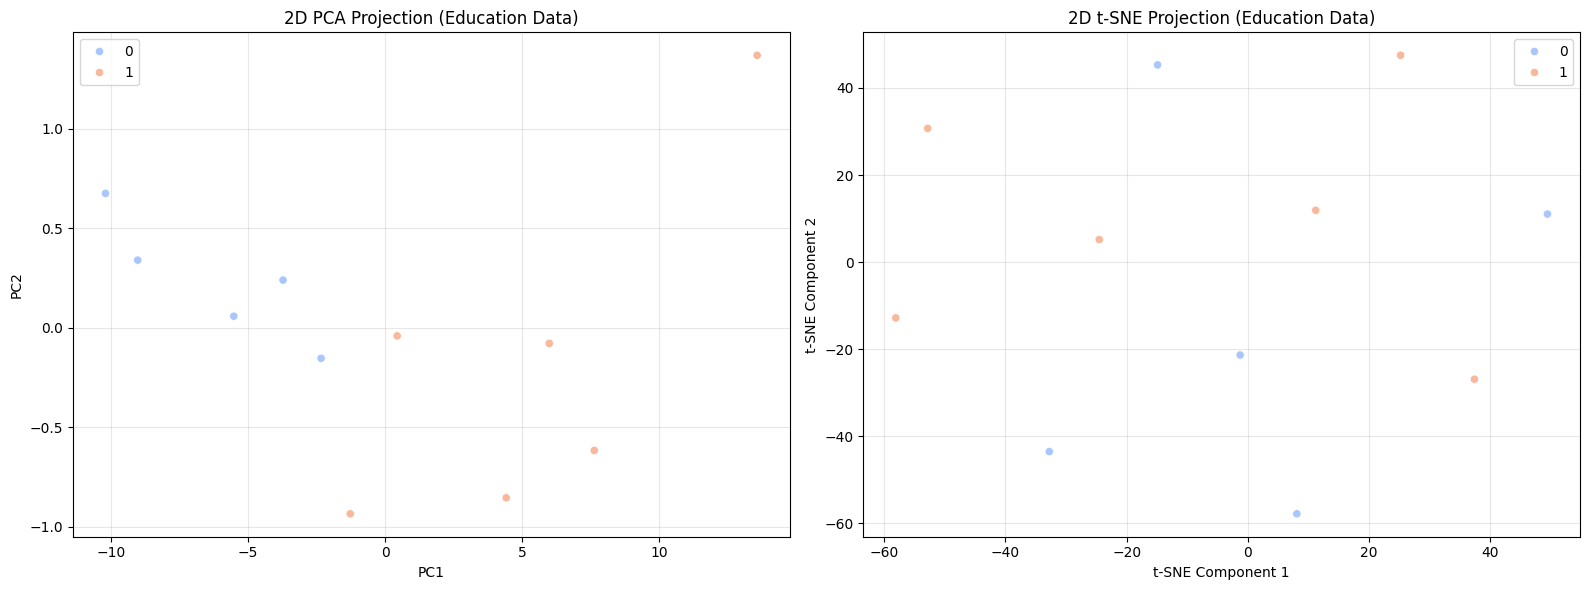

In [18]:
# Apply 2D PCA & t-SNE
pca_edu = PCA(n_components=2, random_state=42)
X_pca_edu_2d = pca_edu.fit_transform(X_train_edu_scaled)

tsne_edu = TSNE(n_components=2, perplexity=min(30, len(X_train_edu_scaled) - 1), random_state=42, max_iter=1000)
X_tsne_edu_2d = tsne_edu.fit_transform(X_train_edu_scaled)

# Set up plots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot PCA
sns.scatterplot(x=X_pca_edu_2d[:, 0], y=X_pca_edu_2d[:, 1], hue=y_train_edu, palette='coolwarm', ax=axes[0])
axes[0].set_title('2D PCA Projection (Education Data)')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')
axes[0].grid(True, alpha=0.3)

# Plot t-SNE
sns.scatterplot(x=X_tsne_edu_2d[:, 0], y=X_tsne_edu_2d[:, 1], hue=y_train_edu, palette='coolwarm', ax=axes[1])
axes[1].set_title('2D t-SNE Projection (Education Data)')
axes[1].set_xlabel('t-SNE Component 1')
axes[1].set_ylabel('t-SNE Component 2')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [19]:
# Reduce dimensionality to 90% variance and re-train
pca_90_edu = PCA(n_components=0.90, random_state=42)
X_train_pca_edu = pca_90_edu.fit_transform(X_train_edu_scaled)
X_test_pca_edu = pca_90_edu.transform(X_test_edu_scaled)

clf_pca_edu = RandomForestClassifier(random_state=42)
clf_pca_edu.fit(X_train_pca_edu, y_train_edu)
acc_pca_edu = accuracy_score(y_test_edu, clf_pca_edu.predict(X_test_pca_edu))

# Display summary comparison table
edu_summary = pd.DataFrame({
    'Model Setup': ['Baseline (Original)', 'PCA (Reduced)'],
    'Number of Features': [X_train_edu_scaled.shape[1], pca_90_edu.n_components_],
    'Test Accuracy': [acc_baseline_edu, acc_pca_edu]
})
display(edu_summary)

,Model Setup,Number of Features,Test Accuracy
0,Baseline (Original),50,1.0
1,PCA (Reduced),1,1.0


### State Education Features Correlation Heatmap

We will now compute the Pearson correlation coefficient between each state's educational rates and plot them to visualize the high collinearity.

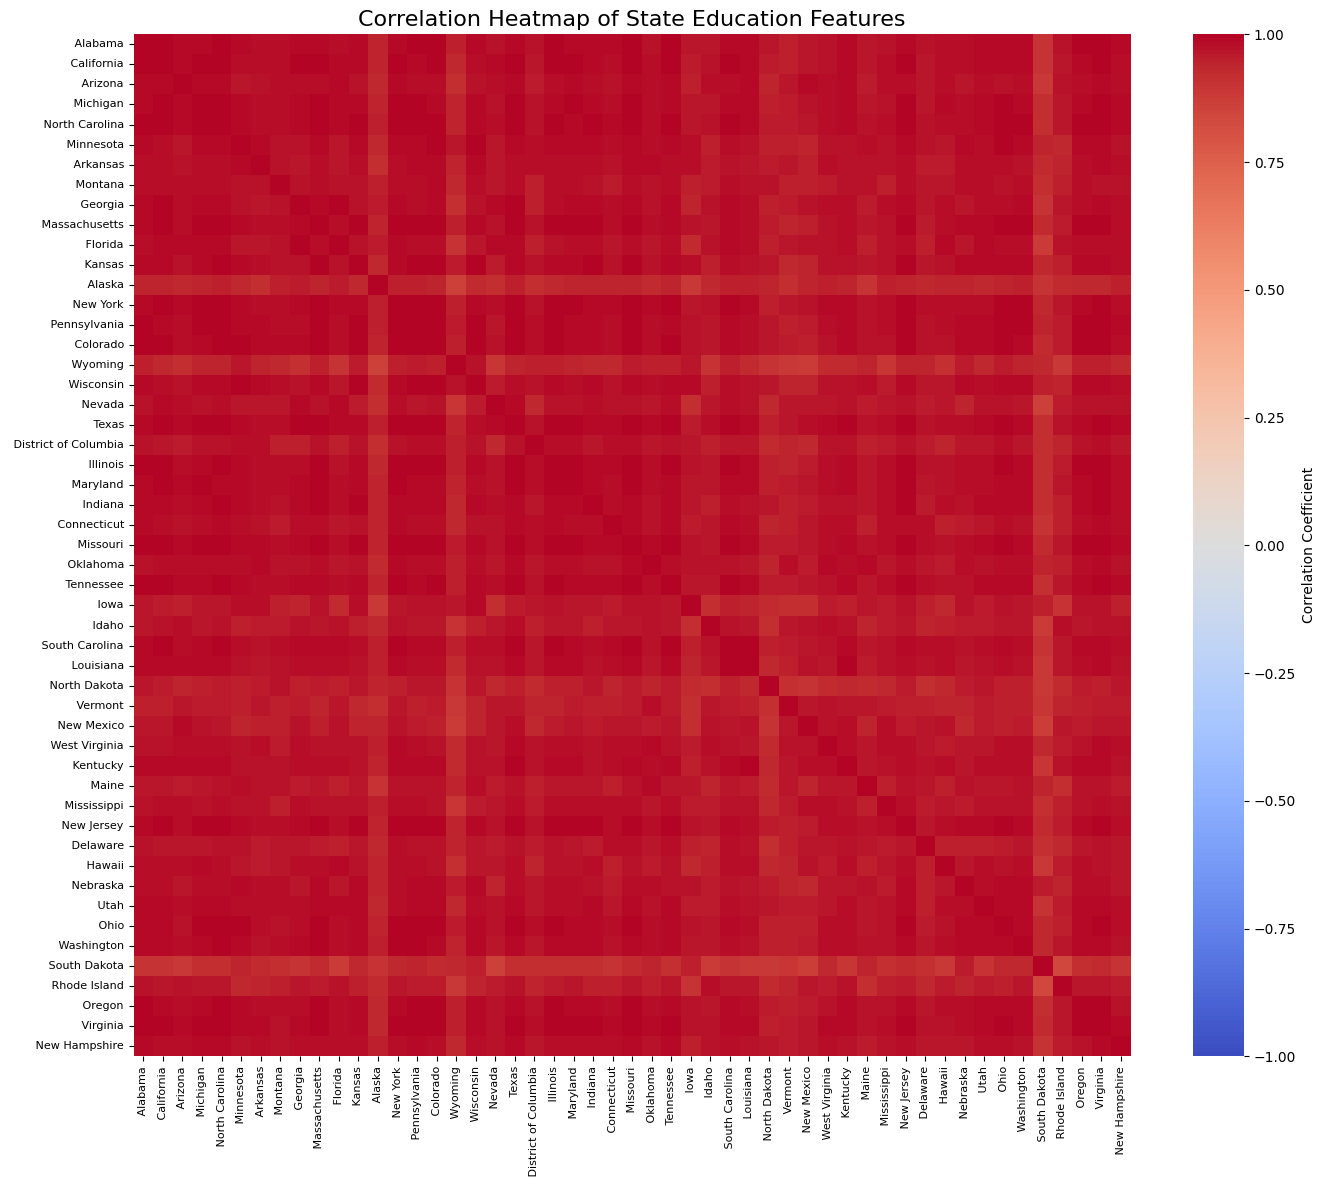

In [20]:
# Calculate the correlation matrix on the numeric state features
corr_matrix = features.corr()

# Plot the correlation heatmap
plt.figure(figsize=(14, 12))
sns.heatmap(
    corr_matrix,
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    xticklabels=True,
    yticklabels=True,
    cbar_kws={'label': 'Correlation Coefficient'}
)
plt.title('Correlation Heatmap of State Education Features', fontsize=16)
plt.xticks(rotation=90, fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

Top 10 States contributing to the First Principal Component:


,State,PC1_Loading,Absolute_Loading
19,Texas,0.143335,0.143335
4,North Carolina,0.143320,0.143320
14,Pennsylvania,0.143243,0.143243
13,New York,0.143160,0.143160
49,Virginia,0.143100,0.143100
25,Missouri,0.143091,0.143091
27,Tennessee,0.143082,0.143082
15,Colorado,0.143046,0.143046
3,Michigan,0.143013,0.143013
39,New Jersey,0.143000,0.143000


/tmp/ipykernel_1973/572796736.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


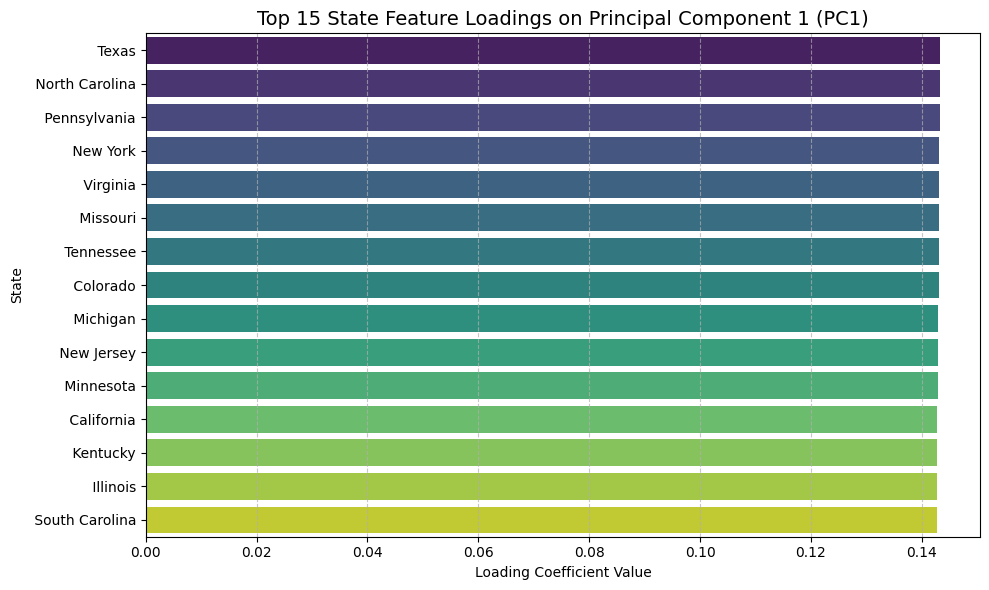

In [21]:
# Get the feature names (states) excluding the target state ' New Hampshire'
state_names = features.drop(columns=[target_col]).columns

# Retrieve PC1 loadings from our fitted PCA model
# Note: pca_90_edu was fit on X_train_edu_scaled
pc1_loadings = pca_90_edu.components_[0]

# Create a DataFrame to inspect loadings
loadings_df = pd.DataFrame({
    'State': state_names,
    'PC1_Loading': pc1_loadings,
    'Absolute_Loading': np.abs(pc1_loadings)
}).sort_values(by='Absolute_Loading', ascending=False)

# Display top 10 contributing states
print("Top 10 States contributing to the First Principal Component:")
display(loadings_df.head(10))

# Plot the top 15 state loadings for PC1
plt.figure(figsize=(10, 6))
sns.barplot(
    x='PC1_Loading',
    y='State',
    data=loadings_df.head(15),
    palette='viridis'
)
plt.title('Top 15 State Feature Loadings on Principal Component 1 (PC1)', fontsize=14)
plt.xlabel('Loading Coefficient Value')
plt.ylabel('State')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Bottom 10 States contributing to the First Principal Component (PC1):


,State,PC1_Loading,Absolute_Loading
41,Hawaii,0.139482,0.139482
40,Delaware,0.139358,0.139358
20,District of Columbia,0.138730,0.138730
47,Rhode Island,0.138397,0.138397
34,New Mexico,0.138181,0.138181
32,North Dakota,0.138132,0.138132
29,Idaho,0.138073,0.138073
33,Vermont,0.137018,0.137018
16,Wyoming,0.135981,0.135981
12,Alaska,0.135631,0.135631


/tmp/ipykernel_1973/2216573234.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


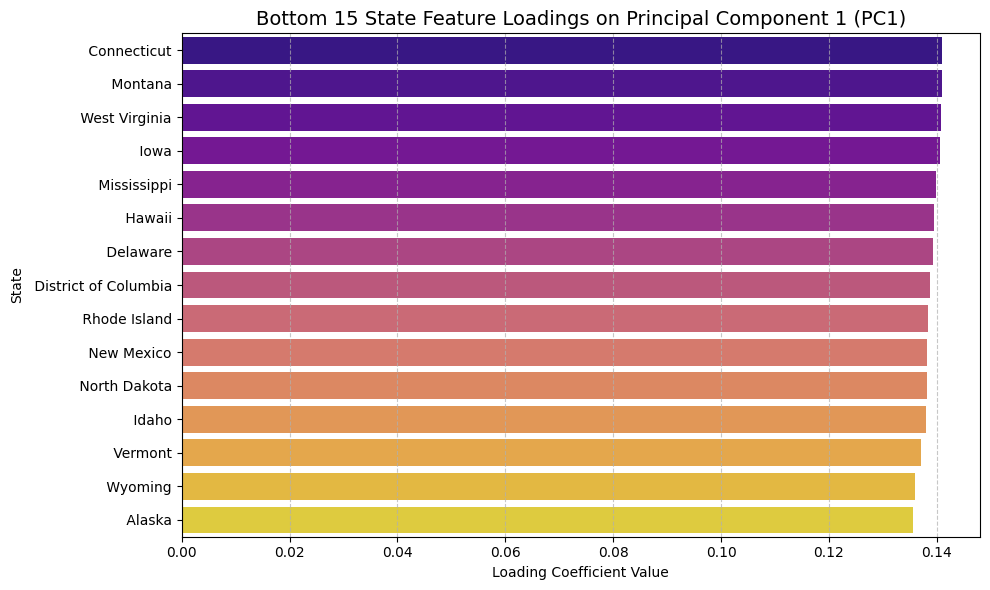

In [22]:
# Display the bottom 10 states contributing to the first principal component
print("Bottom 10 States contributing to the First Principal Component (PC1):")
display(loadings_df.tail(10))

# Plot the bottom 15 state loadings for PC1
plt.figure(figsize=(10, 6))
sns.barplot(
    x='PC1_Loading',
    y='State',
    data=loadings_df.tail(15),
    palette='plasma'
)
plt.title('Bottom 15 State Feature Loadings on Principal Component 1 (PC1)', fontsize=14)
plt.xlabel('Loading Coefficient Value')
plt.ylabel('State')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()